In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import copy
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay, classification_report
import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight

In [2]:
np.random.seed(42)
torch.manual_seed(42)

In [3]:
df = pd.read_csv("IIITH_Codemixed.txt", sep=r"\t", engine="python", header=None, 
                names=["Index", "Sentiment_Text", "Sentiment", "Sentiment_1"])

df = df[["Sentiment_Text", "Sentiment"]]

In [4]:
df.shape

(3879, 2)

In [5]:
df.isnull().sum()

Sentiment_Text    0
Sentiment         0
dtype: int64

In [6]:
print((df["Sentiment"].value_counts(normalize=True)*100).reset_index())

   Sentiment  proportion
0          1   50.451147
1          2   34.854344
2          0   14.694509


In [7]:
def Sentiment_Text_Cleaning(text):
    text = text.strip()
    text = text.lower()
    text = text.replace(":o", "")
    text = text.replace(":)", " ")
    text = text.replace(":(", " ")
    text = text.replace(":-)", " ")
    text = text.replace(":'(", " ")
    text = text.replace("^_^", " ")
    text = text.replace(";-)", " ")
    text = text.replace(";)", " ")
    text = text.replace(":/", " ")
    text = text.replace("~", " ")
    text = text.replace("<3", " ")
    text = text.replace(":*", " ")
    text = text.replace(":-d", " ")
    text = text.replace(":p", " ")
    text = text.replace(":d", " ")
    text = text.replace(":-*", " ")
    text = text.replace(":-(", " ")
    text = text.replace(";->", " ")
    text = text.replace("(:", " ")
    text = text.replace("sirrrr", " sir ")
    text = text.replace("awssmmm", " awesome ")
    text = text.replace("jaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaan", " jaan ")
    text = text.replace("beautyful", " beautiful ")
    text = text.replace("vedio", " video ")
    text = text.replace(" u ", " you ")
    text = text.replace(" salammodi ", " salam modi ")
    text = text.replace(" modiji ", " modi ji ")
    text = text.replace("modiji", " modi ji ")
    text = text.replace("modi ji", " modi ji ")
    text = text.replace(" saal ", " years ")
    text = text.replace("plzzzzzzzzzzzzzzzzzzzzzzzzzzzzzz", " please ")
    text = text.replace("plzzzzzzzzzzzzzzzzzzzzzzzzzzzzz", " please ")
    text = text.replace("plzzzzzzzzzzzzzzzzzzzz", " please ")  
    text = text.replace("plzzzzzzzzzzzzzzzz", " please ")  
    text = text.replace("plzzzzzzzzzzz", " please ")
    text = text.replace("plzzzzzzzzz", " please ")
    text = text.replace("plzzzzzzzz", " please ")
    text = text.replace("plzzzzzz", " please ")
    text = text.replace("plzzzzz", " please ")
    text = text.replace("plzzzz", " please ")
    text = text.replace("plzzz", " please ")
    text = text.replace("plzz", " please ")
    text = text.replace("plz", " please ")
    text = text.replace("modi jee", " modi ji")
    text = text.replace("modije", " modi ji ")
    text = text.replace(" g ", " ji ")
    text = text.replace("i'ts", "its")
    text = text.replace("don't", "dont")
    text = text.replace("i'm", "i am")
    text = text.replace("it's", "its")
    text = text.replace("˜", " ")
    text = text.replace("â", " ")
    text = text.replace("€", " ")
    text = text.replace("ž", " ")
    text = text.replace("å", " ")
    text = text.replace("¹", " ")
    text = text.replace("¤", " ")
    text = text.replace("bhaiiiiiiiiiiiiiiiiiii", " bhai ")
    text = text.replace("bhaiiiiiiiiii", " ")
    text = text.replace("bhaiiiiiii", " ")
    text = text.replace("bhaiiiii", " bhai ")
    text = text.replace("bhaiiii", " bhai ")
    text = text.replace("bhaiii", " bhai ")
    text = text.replace("bhaii", " bhai ")
    text = text.replace("luvvv", " love ")
    text = text.replace("luvv", " love ")
    text = text.replace("luvs", " love ")
    text = text.replace("luv", " love ")
    text = text.replace("?", " ")
    text = text.replace("!", " ")
    text = text.replace("plssssss", " please ")
    text = text.replace("plssss", " please ")
    text = text.replace("plsss", " please ")
    text = text.replace("plss", " please ")
    text = text.replace("pls", " please ")
    text = text.replace("cme", " come ")
    text = text.replace("rpy", " reply ")
    text = text.replace("blockbaster", " blockbuster ")
    text = text.replace("awsome", " awesome ")
    text = text.replace("modig", " modi ji ")
    text = text.replace("[", " ")
    text = text.replace("`", " ")
    text = text.replace(" & ", " and ")
    text = text.replace('"', " ")
    text = text.replace("*", " ")
    text = text.replace("jaooooooooooooooo", " jao ")
    text = text.replace(" msg ", " message ")
    text = text.replace("\\", " ")
    text = text.replace("$@lute", " salute ")
    text = text.replace("$", " ")
    text = text.replace("%", " percent ")
    text = text.replace("bettry", " battery ")
    text = text.replace("&", " ")
    text = text.replace("(", " ")
    text = text.replace(")", " ")
    text = text.replace(" r ", " are ")
    text = text.replace(" u ", " you ")
    text = text.replace("-", " ")
    text = text.replace("<b>", " ")
    text = text.replace("<", " ")
    text = text.replace(">", " ")
    text = text.replace("=", " ")
    text = text.replace("soooooooooooooooooooooooooooooooooooooo", " so ")
    text = text.replace("mich", " much ")
    text = text.replace(" sallu ", " salman ")
    text = text.replace("sallumeya", " salman ")
    text = text.replace("salluuuuuuu", " salman ")
    text = text.replace("salluuuu", " salman ")
    text = text.replace("salluuu", " salman ")
    text = text.replace("salluu", " salman ")
    text = text.replace("sallu", " salman ")
    text = text.replace("+", " ")
    text = text.replace("omg", "oh my god ")
    text = text.replace("piz", " please ")
    text = text.replace("contect", " contact ")
    text = text.replace("2015", " ")
    text = text.replace("2017", " ")
    text = text.replace("11;30", " 11:30 ")
    text = text.replace(";", " ")
    text = text.replace("livestream.com/fblive/salmankhan", " ")
    text = text.replace("itttttttttt", " it ")
    text = text.replace("hittt", " hit ")
    text = text.replace("in shah allah", " ")
    text = text.replace("hiiiiiiiiiiii", " hi ")
    text = text.replace(" im ", " i am ")
    text = text.replace(" no. ", " number ")
    text = text.replace(" no.", " number ")
    text = text.replace("no.diziye", " number diziye ")
    text = text.replace("hiiiiiiiii", " hi ")
    text = text.replace("hiiiiiii", " hi ")
    text = text.replace("hiiiii", " hi ")
    text = text.replace("hiiii", " hi ")
    text = text.replace("hiii", " hi ")
    text = text.replace("hii ", " hi ")
    text = text.replace("commt", "comment")
    text = text.replace("salmannnnnnnn", " salman ")
    text = text.replace("salmannnnnn", " salman ")
    text = text.replace("salmannnnn", " salman ")
    text = text.replace("pilz", " please ")
    text = text.replace("govt", " government ")
    text = text.replace("realllllly", " really ")
    text = text.replace("realy", "really")
    text = text.replace("loook", " look ")
    text = text.replace("supprrrrrrrrrrrrrrr", " super ")
    text = text.replace("’", " ")
    text = text.replace("..................................", " ")
    text = text.replace("..............................", " ")
    text = text.replace("......................", " ")
    text = text.replace(".....................", " ")
    text = text.replace(".................", " ")
    text = text.replace("................", " ")
    text = text.replace("...............", " ")
    text = text.replace("..............", " ")
    text = text.replace("............", " ")
    text = text.replace("...........", " ")
    text = text.replace("..........", " ")
    text = text.replace(".........", " ")
    text = text.replace("........", " ")
    text = text.replace(".......", " ")
    text = text.replace("......", " ")
    text = text.replace(".....", " ")
    text = text.replace("....", " ")
    text = text.replace("...", " ")
    text = text.replace("..", " ")
    text = text.replace(",", " ")
    text = text.replace("o.o o.o", " ")
    text = text.replace("haiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiii", " hai ")
    text = text.replace("haiiiiiiiiiiii", " hai ")
    text = text.replace("haiiiiiii", " hai ")
    text = text.replace("haiiiiii", " hai ")
    text = text.replace("haii", " hai ")
    text = text.replace(" 3:30pm ", " ")
    text = text.replace("4pm ", " ")
    text = text.replace(" 3.30pm ", " ")
    text = text.replace(" 4:00pm ", " ")
    text = text.replace(" 4 pm ", " ")
    text = text.replace(" 4pm", " ")
    text = text.replace(" 5pm ", " ")
    text = text.replace(" 4.02pm", " ")
    text = text.replace(" 4.3 pm", " ")
    text = text.replace(" 4.o6pm", " ")
    text = text.replace(" 4:10pm ", " ")
    text = text.replace(" .4.13pm ", " ")
    text = text.replace(" 4.00pm ", " ")
    text = text.replace("¦", " ")
    text = text.replace(" nic ", " nice ")
    text = text.replace("grt ", " great ")
    text = text.replace(" u ", " you ")
    text = text.replace(" lv ", " love ")
    text = text.replace(" ur ", " your ")
    text = text.replace("shalluuuu", " salman ")
    text = text.replace("shalu", " salman ")
    text = text.replace("salmon", " salman ")
    text = text.replace("hmmmmmm", " hmm ")
    text = text.replace("hmmmmm", " hmm ")
    text = text.replace("hmmmm", " hmm ")
    text = text.replace("hmmm", " hmm ")
    text = text.replace("flim", " film ")
    text = text.replace("i'll", " i will ")
    text = text.replace("plizz", " please ")
    text = text.replace("pliz", " please ")
    text = text.replace(" n3w ", " new  ")
    text = text.replace("amazngggggg", "amazing")
    text = text.replace(" 3:30 pm ", " ")
    text = text.replace("3.30 pm ", " ")
    text = text.replace("4 pm ", " ")
    text = text.replace(" 5:00 pm ", " ")
    text = text.replace(" 4:00 pm ", " ")
    text = text.replace("5 pm ", " ")
    text = text.replace(" 4.30 pm ", " ")
    text = text.replace(" pm ", " prime minister ")
    text = text.replace("pm ", "  prime minister  ")
    text = text.replace("modi sarkar pm", " modi sarkar prime minister ")
    text = text.replace(" vry ", " very ")
    text = text.replace("p.m.", " prime minister ")
    text = text.replace("pm.", " prime minister ")
    text = text.replace(" p.m ", " prime minister ")
    text = text.replace("suuuuuupppppppeeeeeeerrrrrrrrrr", " super ")
    text = text.replace(":", " ")
    text = re.sub(r"\d", " ", text)
    text = text.replace(".", " ")
    text = text.replace("lllllllloooooooovvvvvvvvvvveeeeeeee", " love ")
    text = text.replace("loveeeeeeeeeeeeeeeeeeeeeeeeee", " love ")
    text = text.replace("loveeeeeeeeeeeeeeeeeeeeeeee", " love ")
    text = text.replace("loveeeeeee", " love ")
    text = text.replace("loveeeeee", " love ")
    text = text.replace("loveeee", " love ")
    text = text.replace("loveee", " love ")
    text = text.replace("lovee", " love ")
    text = text.replace("youuuuuu", " you ")
    text = text.replace("youuuu", " you ")
    text = text.replace("youui", " you ")
    text = text.replace(" u ", " you ")
    text = text.replace(" uuuuuuuuuuuuuuuuuuuuuuuuuuuu ", " you ")
    text = text.replace(" uuuuuuuuuuuuuuuuuuuuuu ", " you ")
    text = text.replace(" uuuuuuuuuuu ", " you ")
    text = text.replace(" uuuuuuuuuu ", " you ")
    text = text.replace(" uuuuuuu ", " you ")
    text = text.replace(" uuuuuii ", " you ")
    text = text.replace(" uuuuuuu", " you ")
    text = text.replace("sallllluuuu", " salman ")
    text = text.replace(" uuuu ", " you ")
    text = text.replace(" uuuuh ", " you ")
    text = text.replace(" uuu ", " you ")
    text = text.replace("shallluuuuu", " salman ")
    text = text.replace(" uuu", " you ")
    text = text.replace(" uu ", " you ")
    text = text.replace(" sllu ", " you ")
    text = text.replace("salllu ", " you ")
    text = text.replace("salllluuuu", " salman ")
    text = text.replace(" saallllluuuu ", " salman ")
    text = text.replace("sallluuuuuuuuuuu ", " salman ")
    text = text.replace("uallu", " ullu ")
    text = text.replace("sallluuuu", " salman ")
    text = text.replace("yahooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooo", " yahoo ")
    text = text.replace("niceeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeee", " nice ")
    text = text.replace("niceeeeeeee", " nice ")
    text = text.replace("nicee", " nice ")
    text = text.replace("sooooooooooo", " so ")
    text = text.replace("soooooooo", " so ")
    text = text.replace("sooooo", " so ")
    text = text.replace("soooo", " so ")
    text = text.replace(" sooo ", " so ")
    text = text.replace(" soo ", " so ")
    text = text.replace(" ur ", " yours ")
    text = text.replace(" superr ", " super ")
    text = text.replace(" pleze ", " please ")
    text = text.replace("palz", " please ")
    text = text.replace("¡", " ")
    text = text.replace("«", " ")
    text = text.replace(" lov ", " love ")
    text = text.replace("plllssssss", " please ")
    text= text.replace("#salmankhan", " ")
    text = text.replace("#beingsalmankhan", " ")
    text = text.replace("#bbthiseid" , " ")
    text = text.replace("#aajkiparty", " ")
    text = text.replace("#bajrangibhaijan", " ")
    text = text.replace("#bajarangi_bhaijaan", " ")
    text = text.replace("#bhaiyjan", " ")
    text = text.replace("#salu", " ")
    text = text.replace("#salman_bhai", " ")
    text = text.replace("#salmankhan", " ")
    text = text.replace("#bajrangi", " ")
    text = text.replace("#bhaijan", " ")
    text = text.replace("#juma", " ")
    text = text.replace("#roza", " ")
    text = text.replace("#bhai", " ")
    text = text.replace("#being_human", " ")
    text = text.replace("#aaj", " ")
    text = text.replace("#sabhi", " ")
    text = text.replace("#superhits", " ")
    text = text.replace("#superdupar", " ")
    text = text.replace("#salman_sir", " ")
    text = text.replace("#chhattishgadiya_sable_badiya", " ")
    text = text.replace("i_love_u", " i love you ")
    text = text.replace("#akki", " ")
    text = text.replace("#nadim_shaikh", " ")
    text = text.replace("#hanuman", " ")
    text = text.replace("#salman", " ")
    text = text.replace("#pandey", " ")
    text = text.replace("#swagat", " ")
    text = text.replace("#khan", " ")
    text = text.replace("#kuchh_khas", " ")
    text = text.replace("#swachhbharat", " ")
    text = text.replace("#livechatwithsalmankhan", " ")
    text = text.replace("#tc", " ")
    text = text.replace("#uhh", " ")
    text = text.replace("#salman_khan", " ")
    text = text.replace("#acount", " ")
    text = text.replace("#page", " ")
    text = text.replace("#sunati", " ")
    text = text.replace("#uturn", " ")
    text = text.replace("#aamaal", " ")
    text = text.replace("#imaan", " ")
    text = text.replace("#pakka", " ")
    text = text.replace("#sona", " ")
    text = text.replace("#sir", " ")
    text = text.replace("#", " ")
    text = text.replace("salmaannnnnnnnmnmm", " salman ")
    text = text.replace("salmaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaan", " salman ")
    text = text.replace("salmaan", " salman ")
    text = text.replace("@lwayz", " always ")
    text = text.replace("@beingsalmankhan", " ")
    text = text.replace("@bb", " ")
    text = text.replace("@", " ")
    text = text.replace("hoga modi g", " hoga modi ji ")
    text = text.replace("saath modi g", " saath modi ji ")
    text = text.replace(" modi g ", " modi ji ")
    text = text.replace("____", " ")
    text = text.replace("'", " ")
    text = text.replace("pleze", " please ")
    text = text.replace("bhauiiiiiii", " bhai ")
    text = text.replace(" fac ", " face ")
    text = text.replace(" mach ", " much ")
    text = text.replace("loveu tooooo your vey handsam", " love you to your very handsome")
    text = text.replace(" iloveu ", " i love you ")
    text = text.replace("loooovvv", " love ")
    text = text.replace("ho i love u", " ho i love you ")
    text = text.replace(" ilove you", " i love you ")
    text = text.replace(" bhaiyou ", " bhai you ")
    text = text.replace("osmmmm", " awesome ")
    text = text.replace("osm", " awesome ")
    text = text.replace("waoooooo", " wow ")
    text = text.replace("waoo ", " wow ")
    text = text.replace("wao ", " wow ")
    text = text.replace("bhaaiii", " bhai ")
    text = text.replace(" gud ", " good ")
    text = text.replace("mmubarak", " mubarak ")
    text= text.replace("eidmubarakh", " eid mubarak")
    text = text.replace("mubarakh", " mubarak ")
    text = text.replace("sllam", " salam ")
    text = text.replace("lov ", " love ")
    text = text.replace(" ji grat", " ji great")
    text = text.replace(" grate ", " great ")
    text = text.replace(" ji grat", " ji great")
    text = text.replace(" grateman", " great man ")
    text = text.replace(" grat", " great ")
    text = text.replace(" urs ", " yours ")
    text = text.replace(" urs", " yours ")
    text = text.replace(" firr ", " fir ")
    text = text.replace(" firr", " fir ")
    text = text.replace(" supar ", " super ")
    text = text.replace("suparhit", " super hit ")
    text = text.replace("supar ", " super ")
    text = text.replace("suparhit", " super hit ")
    text = text.replace("superhit", " super hit ")
    text = text.replace(" bajrangibhai ", " bajrangi bhai ")
    text = text.replace("bhaijan", " bhaijaan ")
    text = text.replace("saloo", " salman ")
    text = text.replace("”", " ")
    text = text.replace("²", " ")
    text = text.replace("_", " ")
    text = text.replace("–", " ")
    text = text.replace("ã", " ")
    text = text.replace("/", " ")
    text = text.replace("", " ")
    text = text.replace("baiiii", " bhai ")
    text = text.replace("bhijaan", " bhaijaan ")
    text = text.replace("v good ", " very good ")
    text = text.replace(" mashaalllah ", " masha allah ")
    text = text.replace(" mashallallah ", " masha allah ")
    text = text.replace(" mashallah", " masha allah ")
    text = text.replace("mashallah ", " masha allah ")
    text = text.replace(" comments ", " comment ")
    text = text.replace("p m ho ", " prime minister ho ")
    text = text.replace("p m ji ", " prime minister ji ")
    text = text.replace("p m sab ", " prime minister sab ")
    text = text.replace("pradhanmantriji", " prime minister ")
    text = text.replace(" preiminister ", " prime minister ")
    text = text.replace("hallo", " Hello ")
    text = text.replace(" bhai jaannnnnnn", " bhaijaan ")
    text = text.replace("owsome", " awesome ")
    text = text.replace(" congratulations ", " congrats ")
    text = text.replace("congratulation ", " congrats ")
    text = text.replace(" congratulated", " congrats ")
    text = text.replace("addd mee frnds", " add me friends ")
    text = text.replace("onli ", " only ")
    text = text.replace(" hia", " hai ")
    text = text.replace("hooooooooooooo", " ho ")
    text = text.replace("rajesthan", " rajasthan ")
    text = text.replace("namaaz", " namaz ")
    text = text.replace("loveyou", " love you ")
    text = text.replace("superbbbbbbbbbb", " superb ")
    text = text.replace("mand bloing", " mind blowing ")
    text = text.replace("pakishtan", " pakistan ")
    text = text.replace("welcomes", " welcome ")
    text = text.replace(" disst ", " district ")
    text = text.replace("businesses", " business ")
    text = text.replace("bhai jan", " bhaijaan ")
    text = text.replace(" cal ", " call ")
    text = text.replace("handsom ", " handsome ")
    text = text.replace("bhai jaan", " bhaijaan ")
    text = text.replace(" frnd ", " friend ")
    text = text.replace("friends", " friend ")
    text = text.replace("movies", " movie ")
    text = text.replace("supper", " super ")
    text = text.replace("plllzzzzzz", " please ")
    text = text.replace(" g ", " ji ")
    text = text.replace("skil india", " skill india")
    text = text.replace(" thm ", " them ")
    text = text.replace(" cuttin ", " cutting ")
    text = text.replace("majid", " masjid ")
    text = text.replace("ohhhh", " oh ")
    text = text.replace(" myy ", " my ")
    text = text.replace(" hlw", " hello ")
    text = text.replace("ohhh", " oh ")
    text = text.replace("bhaaaaaaaaaaaaaaaai", " bhai ")
    text = text.replace("haaaaaaaaa", " ha ")
    text = text.replace("heloo", " hello ")
    text = text.replace(" cnt ", " cant ")
    text = text.replace(" phon ", " phone ")
    text = text.replace("yarrrrr", " yaar ")
    text = text.replace(" nhi ", " nahi ")
    text = text.replace(" pic ", " picture ")
    text = text.replace(" pics ", " picture ")
    text = text.replace(" vry ", " very ")
    text = text.replace(" nce ", " nice ")
    text = text.replace("bjrngi bhi jan", " bajrangi bhaijaan ")
    text = text.replace("saluuuuuuu", " salman ")
    text = text.replace(" saab ", " sahab ")
    text = text.replace("thnx", " thanks ")
    text = text.replace("movieeee", " movie ")
    text = text.replace("moviee", " movie ")
    text = text.replace(" movi ", " movie ")
    text = text.replace(" frnshp ", " friendship ")
    text = text.replace("films", " film ")
    text = text.replace("aslamolikum", " assalamu alaikum ")
    text = text.replace("asslamu alyekum", " assalamu alaikum ")
    text = text.replace("assalamualikum", " assalamu alaikum ")
    text = text.replace("aslma alikum", " assalamu alaikum ")
    text = text.replace("aslamo alaikum", " assalamu alaikum ")
    text = text.replace("as salamolay kum", " assalamu alaikum ")
    text = text.replace("vai jan", "bhaijaan")
    text = text.replace("salam lekum", " assalamu alaikum ")
    text = text.replace("assalamu alykum", " assalamu alaikum ")
    text = text.replace("salame walekum", " assalamu alaikum ")
    text = text.replace(" bai ", " bhai ")
    text = text.replace("yrrrr", " yaar ")
    text = text.replace(" wroung ", " wrong ")
    text = text.replace("wowwwwww", " wow ")
    text = text.replace(" axelent ", " excellent ")
    text = text.replace("asaalam aalay kumm ", " assalamu alaikum ")
    text = text.replace("iam", " i am ")
    text = text.replace(" comnt ", " comment ")
    text = text.replace(" toooo ", " to ")
    text = text.replace(" mache ", " much ")
    text = text.replace(" dest ", " best ")
    text = text.replace(" actar ", " actor ")
    text = text.replace("actors", " actor ")
    text = text.replace("aslam valekum", " assalamu alaikum ")
    text = text.replace("assala muwalekum", " assalamu alaikum ")
    text = text.replace("assalamualaikum", " assalamu alaikum ")
    text = text.replace("assalaam waalaikum", " assalamu alaikum ")
    text = text.replace("vhai zahan", " bhaijaan ")
    text = text.replace("asslam walekum", " assalamu alaikum ")
    text = text.replace("salam malikkum", " assalamu alaikum ")
    text = text.replace("asslamalaikum", " assalamu alaikum ")
    text = text.replace("assalamwaelkum", " assalamu alaikum ")
    text = text.replace("aslam alekum", " assalamu alaikum ")
    text = text.replace("assalam walekum", " assalamu alaikum ")
    text = text.replace("assalamu aly kum", " assalamu alaikum ")
    text = text.replace("salamin alaykum", " assalamu alaikum ")
    text = text.replace("assalaam o alaikum", " assalamu alaikum ")
    text = text.replace("aslaam o elekum", " assalamu alaikum ")
    text = text.replace("asssalamalaikum", " assalamu alaikum ")
    text = text.replace("assalam walaikum", " assalamu alaikum ")
    text = text.replace("assalam o alaikum", " assalamu alaikum ")
    text = text.replace("asslam alykum", " assalamu alaikum ")
    text = text.replace("aksle wale kum", " assalamu alaikum ")
    text = text.replace("balkum salam", " assalamu alaikum ")
    text = text.replace("hloo", " hello ")
    text = text.replace("bhaaaiiiii", " bhai ")
    text = text.replace("alooottt", " a lot ")
    text = text.replace(" cmnt ", " comment ")
    text = text.replace("salam sir", " salman sir ")
    text = text.replace ("khanhum", " khan hum ")
    text = text.replace(" bhia ", " bhai ")
    text = text.replace("howz", " how ")
    text = text.replace("possibleee", " possible ")
    text = text.replace("rply", " reply ")
    text = text.replace("assalamalikum", " assalamu alaikum ")
    text = text.replace("as salam walekum", " assalamu alaikum ")
    text = text.replace("asalamwalaikum", " assalamu alaikum ")
    text = text.replace("bolywood", " bollywood ")
    text = text.replace(" allaha ", " allah ")
    text = text.replace("allaha ", " allah ")
    text = text.replace("becous", " because ")
    text = text.replace("salmanu", " salman ")
    text = text.replace("hamsome", " handsome ")
    text = text.replace(" inshaa ", " insha ")
    text = text.replace("inshallah", " insha allah ")
    text = text.replace("inshallha", " insha allah ")
    text = text.replace("lv you", " love you ")
    text = text.replace("salmn", " salman ")
    text = text.replace("amazinggg", " amazing ")
    text = text.replace("wonderfullll", "wonderfull")
    text = text.replace("greatttt", " great ")
    text = text.replace("luke", " like ")
    text = text.replace("hllo", " hello ")
    text = text.replace("gud", " good ")
    text = text.replace("nyt", " night ")
    text = text.replace("frm", " from ")
    text = text.replace("nic ", " nice ")
    text = text.replace("salman bai", " salman bhai ")
    text = text.replace("baigan", " bhaijaan ")
    text = text.replace("bai ji ", " bhai ji ")
    text = text.replace(" i m ", "i am ")
    text = text.replace("biggggest", " biggest ")
    text = text.replace("aslo", " also ")
    text = text.replace(" alah ", " allah ")
    text = text.replace("niht", " night ")
    text = text.replace("alwyzz", " always ")
    text = text.replace("salmania", " salman ")
    text = text.replace("knw", " know ")
    text = text.replace("missss", " miss ")
    text = text.replace("commentment", " commitment ")
    text = text.replace("asalam o alekum", " assalamu alaikum ")
    text = text.replace("asalam you alekom", " assalamu alaikum ")
    text = text.replace("bhaijaaan", " bhaijaan ")
    text = text.replace("bummprrr", " bumper ")
    text = text.replace("in saahallah", " insha allah ")
    text = text.replace("touching movi", " touching movie ")
    text = text.replace(" fans ", " fan ")
    text = text.replace("addme", " add me ")
    text = text.replace("orissa", " odisha ")
    text = text.replace(" parson ", " person ")
    text = text.replace(" krlo ", " karlo ")
    text = text.replace("p m modi", " prime minister modi ")
    text = text.replace("freind", " friend ")
    text = text.replace("h w are y ", " how are you ")
    text = text.replace("sallo", " salman ")
    text = text.replace("salmankhan", " salman Khan ")
    text = text.replace(" tym ", " time ")
    text = text.replace("whr are u", " where are you ")
    text = text.replace("aurrrrr", " aur ")
    text = text.replace("hindustan", " india ")
    text = text.replace("indian", " india ")
    text = text.replace(" mubark ", " mubarak ")
    text = text.replace("yessss", " yes ")
    text = text.replace("cuteee", " cute ")
    text = text.replace("lubbbbb", " love ")
    text = text.replace("mubbark", " mubarak ")
    text = text.replace("prty", " party ")
    text = text.replace("thaeid", " tha eid ")
    text = text.replace("sallman", " salman ")
    text = text.replace("mobarak", " mubarak ")
    text = text.replace("bahi jan", " bhaijaan ")
    text = text.replace(" mach", " much ")
    text = text.replace("ramazan", " ramadan ")
    text = text.replace("ramajan", " ramadan ")
    text = text.replace("vrrrry", " very ")
    text = text.replace("vrryy", " very ")
    text = text.replace("salu bhi", " salman bhai ")
    text = text.replace("saluuuu", " salman ")
    text = text.replace("oooops", " oops ")
    text = text.replace("onliy", " only ")
    text = text.replace("niece", " nice ")
    text = text.replace("turkmenistan", " turkey ") 
    text = text.replace("turkes", " turkey ")
    text = text.replace("likeeee", " like ")
    text = text.replace(" karooooo ", " karo ")
    text = text.replace("bhaaaaayi", " bhai ")
    text = text.replace("comee", " come ")
    text = text.replace("allready", " already ")
    text = text.replace(" jee ", " ji ")
    text = text.replace("lovly ", " lovely ")
    text = text.replace("bhaijine", " bhaijaan ")
    text = text.replace("filam", " film ")
    text = text.replace(" vai ", " bhai ")
    text = text.replace("vaijan", " bhaijaan ")
    text = text.replace("vaijaan", " bhaijaan ")
    text = text.replace(" sr ", " sir ")
    text = text.replace("awxom", " awesome ")
    text = text.replace("hitz", " hits ")
    text = text.replace("mohammed", " muhammad ")
    text = text.replace(" pla ", " please ")
    text = text.replace("iike", " like ")
    text = text.replace("saluu", " salman ")
    text = text.replace("u welakam", " you welcome ")
    text = text.replace("a foll", " a fool ")
    text = text.replace("hahahahahahaha", " haha ")
    text = text.replace("hahahahahah", " haha ")
    text = text.replace("hahaha", " haha ")
    text = text.replace("pleaseeee", " please ")
    text = text.replace("v e are y", " very ")
    text = text.replace("bhailove", " bhai love ")
    text = text.replace("ilove ", " i love ")
    text = text.replace(" filmo ", " film ")
    text = text.replace("woowww", " wow ")
    text = text.replace("becaymuse", " because ")
    text = text.replace("musalman", " muslim ")
    text = text.replace("hendu", " hindu ")
    text = text.replace("hinduo", " hindu ")
    text = text.replace(" indiya ", " india ")
    text = text.replace("bhrat", " bharat ")
    text = text.replace("chirman", " chairman ")
    text = text.replace("slman", " salman ")
    text = text.replace("thnks", " thanks ")
    text = text.replace("paaaakkkiiissstan", " pakistan ")
    text = text.replace(" sall ", " salman ")
    text = text.replace("hlw", " hello ")
    text = text.replace(" kro ", " karo ")
    text = text.replace(" bcoz ", " because ")
    text = text.replace(" wid u", " with you ")
    text = text.replace(" kr lo ", " karlo ")
    text = text.replace("hlo ", " hello ")
    text = text.replace(" juma ", " junna ")
    text = text.replace("amzing", " amazing ")
    text = text.replace(" trealir ", " trailer ")
    text = text.replace("asslamualeykum", " assalamu alaikum ")
    text = text.replace("alsooo", " also ")
    text = text.replace("watcing", " watching ")
    text = text.replace("nyxc", " nice ")
    text = text.replace(" fr ", " for ")
    text = text.replace("bhai jaaaan", " bhaijaan ")
    text = text.replace(" lukin ", " looking ")
    text = text.replace(" salu ", " salman ")
    text = text.replace("salmaaaan", " salman ")
    text = text.replace("bhaijaaaaannnn", " bhaijaan ")
    text = text.replace("pleace", " please ")
    text = text.replace("asalmwale coom", " assalamu alaikum ")
    text = text.replace("alwys wth u", " always with you ")
    text = text.replace("yooou", " you ")
    text = text.replace("jumaa", " jumma ")
    text = text.replace(" camme ", " come ")
    text = text.replace(" camm amaroc ", " come ")
    text = text.replace("jaihind", " jai hind ")
    text = text.replace(" krrrr ", " karo ")
    text = text.replace("naice", " nice ")
    text = text.replace("bst", " best ")
    text = text.replace("lck", " luck ")
    text = text.replace("as salam alaikom", " assalamu alaikum ")
    text = text.replace(" cm ", " come ")
    text = text.replace("bht", " bahut ")
    text = text.replace("aallaahh", " allah ")
    text = text.replace("b hi jaan", " bhaijaan ")
    text = text.replace("wishing", " wish ")
    text = text.replace(" wishes ", " wish ")
    text = text.replace("rocxxx", " ")
    text = text.replace("buhubali", " bahubali ")
    text = text.replace("awsm", " awesome ")
    text = text.replace(" fst dy fst shw", " first day first show ")
    text = text.replace("gguyssss", " guys ")
    text = text.replace("guyssss", " guys ")
    text = text.replace("uplod", " upload ")
    text = text.replace("bhaijaaaannnnn", " bhaijaan ")
    text = text.replace("awesomee", " awesome ")
    text = text.replace("massage", " message ")
    text = text.replace("masig", " message ")
    text = text.replace("banjrangi", " bajrangi ")
    text = text.replace("fenss", " fan ")
    text = text.replace("bahutt", " bahut ")
    text = text.replace("tommorow", " tomorrow ")
    text = text.replace("offical", " official ")
    text = text.replace("i shw your", "i saw your ")
    text = text.replace(" al movie", " all movie ")
    text = text.replace("thuuuu", " tu ")
    text = text.replace("adress", " address ")
    text = text.replace(" itx ", " its ")
    text = text.replace(" thiz ", " this ")
    text = text.replace("bahizan", " bhaijaan ")
    text = text.replace("bodyguardwe", " bodyguard we ")
    text = text.replace(" redy ", " ready ")
    text = text.replace("bolliwood", " bollywood ")
    text = text.replace("floop", " flop ")
    text = text.replace("guaranteed", " guarantee ")
    text = text.replace("downlod", " download ")
    text = text.replace("hppy", " happy ")
    text = text.replace(" wsh ", " wish ")
    text = text.replace("bhaijhan", " bhaijaan ")
    text = text.replace(" z zzzzzzz zz", " ")
    text = text.replace("dout", " doubt ")
    text = text.replace("therator", " theatre ")
    text = text.replace("duperhit", " duper hit ")
    text = text.replace("flog", " flop ")
    text = text.replace("muslimo", " muslim ")
    text = text.replace("baout", " bahut ")
    text = text.replace("godbless", " god bless ")
    text = text.replace("veri", " very ")
    text = text.replace("supose", " suppose ")
    text = text.replace(" ead ", " eid ")
    text = text.replace("caror", " crore ")
    text = text.replace("crores", " crore ")
    text = text.replace("acter", " actor ")
    text = text.replace("thujhse", " tujse ")
    text = text.replace(" can t wiat ", " cant wait ")
    text = text.replace("friende", " friend ")
    text = text.replace("bodegurd", " bodyguard ")
    text = text.replace("shyadi", " shaadi ")
    text = text.replace("shayadi", " shaadi ")
    text = text.replace("mubharak", " mubarak ")
    text = text.replace("bahout", " bahut ")
    text = text.replace("suprb", " superb ")
    text = text.replace("faan", " fan ")
    text = text.replace("hafis", " hafiz ")
    text = text.replace("tailor", " trailor ")
    text = text.replace("eidmubarak", "eid mubarak ")
    text = text.replace("thiseid", " this eid ")
    text = text.replace("tobe", " to be ")
    text = text.replace("eidd", " eid ")
    text = text.replace("flap", " flop ")
    text = text.replace("sulltan", " sultan ")
    text = text.replace("inshaallah", " insha allah ")
    text = text.replace("hottt", " hot ")
    text = text.replace("dooper", " duper ")
    text = text.replace("sooper", " super ")
    text = text.replace("gd mrng ", " good morning ")
    text = text.replace("gm salman", " good morning salman ")
    text = text.replace("morening", " morning ")
    text = text.replace(" salaman ", " salman ")
    text = text.replace(" vhai ", " bhai ")
    text = text.replace("fane", " fan ")
    text = text.replace("bollwood", " bollywood ")
    text = text.replace("humanbieng", " human being ")
    text = text.replace("humans", " human ")
    text = text.replace("blance", " balance ")
    text = text.replace("blcne", " balance ")
    text = text.replace("numbr", " number ")
    text = text.replace("bhaijai", " bhaijaan ")
    text = text.replace("vaaijaan", " bhaijaan ")
    text = text.replace("salfish", " selfish ")
    text = text.replace("bhajaan", " bhaijaan ")
    text = text.replace("bollywod", " bollywood ")
    text = text.replace("evry", " every ")
    text = text.replace("cmnts", " comment ")
    text = text.replace("cmnt", " comment ")
    text = text.replace("riply", " reply ")
    text = text.replace("gdnt", " good night ")
    text = text.replace("ryply", " reply ")
    text = text.replace("subhanallah", " subhan allah ")
    text = text.replace("frendns", " friend ")
    text = text.replace("frend", " friend ")
    text = text.replace("frendz", " friend ")
    text = text.replace("qhuran", " quran ")
    text = text.replace("allha", " allah ")
    text = text.replace("bhaizaan", " bhaijaan ")
    text = text.replace("advaance", " advance ")
    text = text.replace("arresst", " arrest ")
    text = text.replace("wth u", " with you ")
    text = text.replace("frndship", " friendship ")
    text = text.replace("bhaijn", " bhaijaan ")
    text = text.replace("shadi", " shaadi ")
    text = text.replace(" fb ", " facebook ")
    text = text.replace("pakistanio", " pakistan ")
    text = text.replace("supr", " super ")
    text = text.replace("hiro", " hero ")
    text = text.replace("favroute", " favourite ")
    text = text.replace("mushalman", " muslim ")
    text = text.replace("frndz", " friend ")
    text = text.replace(" h ", " hai ")
    text = text.replace(" gov ", " government ")
    text = text.replace(" kr ", " kar ")
    text = text.replace(" b ", " bhi ")
    text = text.replace("apki", " aapki ")
    text = text.replace("gya", " gaya ")
    text = text.replace(" pr ", " phir ")
    text = text.replace(" k ", " ke ")
    text = text.replace(" ap ", " aap ")
    text = text.replace(" nai ", " nahi ")
    text = text.replace(" rhe ", " rahe ")
    text = text.replace(" app ", " aap ")
    text = text.replace("muchhhhhhhhhhh", " much ")
    text = text.replace("jannatttttttttt", " jannat ")
    text = text.replace(" taab ", " tab ")
    text = text.replace(" kloi ", " koi ")
    text = text.replace(" men ", " mein ")
    text = text.replace("fanzzzz", " fan ")
    text = text.replace("razan", " ramzan ")
    text = text.replace("ap shdi kar loooo", " aap shaadi karlo ")
    text = text.replace("banaaya", " banaya ")
    text = text.replace("hellooooo", " hello ")
    text = text.replace("danyabaad",  " danyavad ")
    text = text.replace(" pdho ", " padho ")
    text = text.replace(" khushiyo ", "  khushiyon ")
    text = text.replace("ap salman ", "aap salman ")
    text = text.replace(" ich ", " ")
    text = text.replace(" wkt ", " waqt ")
    text = text.replace(" kapada ", " kapda ")
    text = text.replace(" khole ", " khol ")
    text = text.replace(" ldkiya ", " ladki ")
    text = text.replace(" ladkiyan ", " ladki ")
    text = text.replace(" col me", " call me ")
    text = text.replace(" ldki ", " ladki ")
    text = text.replace(" photos ", " photo ")
    text = text.replace(" smilest ", " smile ")
    text = text.replace(" youngest ", " young ")
    text = text.replace(" godfather ", " god father ")
    text = text.replace(" health ", " healthy ")
    text = text.replace(" mmmmuuuuuuaaaaaaahhhhh ", " muah ")
    text = text.replace(" laik ", " like ")
    text = text.replace(" likes ", " like ")
    text = text.replace("muuuhhhhhhaaa", " muah ")
    text = text.replace(" leg ", " lag ")
    text = text.replace(" chorr ", " chor ")
    text = text.replace(" sant ", " send ")
    text = text.replace(" tunes ", " tune ")
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text

In [8]:
df["Cleaned_Sentiment_Text"] = df["Sentiment_Text"].apply(Sentiment_Text_Cleaning)

In [9]:
df = df[df["Cleaned_Sentiment_Text"].str.strip() != ""]

In [10]:
df = df.drop_duplicates(subset=["Cleaned_Sentiment_Text"])

In [11]:
df = df.reset_index(drop=True)

In [12]:
df.shape

(3821, 3)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3821 entries, 0 to 3820
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Sentiment_Text          3821 non-null   object
 1   Sentiment               3821 non-null   int64 
 2   Cleaned_Sentiment_Text  3821 non-null   object
dtypes: int64(1), object(2)
memory usage: 89.7+ KB


In [14]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df, test_size=0.20, random_state=42, stratify=df["Sentiment"])

In [15]:
from tokenizers import Tokenizer
from tokenizers.models import Unigram
from tokenizers.trainers import UnigramTrainer
from tokenizers.pre_tokenizers import Metaspace
from transformers import PreTrainedTokenizerFast

tokenizer = Tokenizer(Unigram())
tokenizer.pre_tokenizer = Metaspace(replacement=" ", prepend_scheme="always")

trainer = UnigramTrainer(
    vocab_size=3500, 
    special_tokens=["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"],
    unk_token="[UNK]"
)

df_train_cleaned = df_train.copy()
df_test_cleaned   = df_test.copy()

df_train_cleaned["Cleaned_Sentiment_Text"] = df_train_cleaned["Cleaned_Sentiment_Text"].fillna("").astype(str).str.strip()
df_test_cleaned["Cleaned_Sentiment_Text"]   = df_test_cleaned["Cleaned_Sentiment_Text"].fillna("").astype(str).str.strip()

df_train_filtered = df_train_cleaned[df_train_cleaned["Cleaned_Sentiment_Text"] != ""].copy()
df_test_filtered   = df_test_cleaned[df_test_cleaned["Cleaned_Sentiment_Text"] != ""].copy()

train_texts  = df_train_filtered["Cleaned_Sentiment_Text"].tolist()
test_inputs   = df_test_filtered["Cleaned_Sentiment_Text"].tolist()

train_labels = df_train_filtered["Sentiment"].values
test_labels   = df_test_filtered["Sentiment"].values

tokenizer.train_from_iterator(train_texts, trainer)

fast_tokenizer = PreTrainedTokenizerFast(
    tokenizer_object=tokenizer, 
    pad_token="[PAD]", 
    unk_token="[UNK]", 
    cls_token="[CLS]", 
    sep_token="[SEP]"
)

def tokenize_dataset(texts):
    return fast_tokenizer(texts, padding="max_length", truncation=True, max_length=42, return_tensors="pt")

train_encodings = tokenize_dataset(train_texts)
test_encodings   = tokenize_dataset(test_inputs)

In [16]:
vec_file_path = "wiki-news-300d-1M-subword.vec"
actual_vocab_size = len(fast_tokenizer)
print("Vocab Size:", actual_vocab_size)

embedding_matrix = np.random.normal(
    scale=0.1,
    size=(actual_vocab_size, 300)
)

vocab = fast_tokenizer.get_vocab()
matched = 0

with open(vec_file_path, "r", encoding="utf-8", errors="ignore") as f:
    next(f)  
    fasttext_dict = {}
    for line in f:
        parts = line.rstrip().split()
        if len(parts) < 301:
            continue
        word = parts[0]
        fasttext_dict[word] = np.asarray(parts[1:301], dtype=np.float32)

for token, idx in vocab.items():
    lookup_token = token.lstrip(" ") 
    
    if lookup_token in fasttext_dict:
        embedding_matrix[idx] = fasttext_dict[lookup_token]
        matched += 1

embedding_matrix = torch.tensor(
    embedding_matrix,
    dtype=torch.float
)

print(
    f"Coverage: {matched}/{actual_vocab_size} "
    f"({matched/actual_vocab_size*100:.2f}%)"
)

Vocab Size: 3482
Coverage: 2628/3482 (75.47%)


In [17]:
train_seq = train_encodings["input_ids"].clone().detach()
test_seq   = test_encodings["input_ids"].clone().detach()

train_y = torch.tensor(train_labels, dtype=torch.long)
test_y   = torch.tensor(test_labels, dtype=torch.long)

train_dataset = TensorDataset(train_seq, train_y)
test_dataset   = TensorDataset(test_seq, test_y)

batch_size = 16

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader   = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [18]:
class SentimentRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers=2, rnn_type="lstm", dropout=0.0, pretrained_embeddings=None):
        super(SentimentRNN, self).__init__()        
        
        if pretrained_embeddings is not None:
            self.embedding = nn.Embedding.from_pretrained(pretrained_embeddings, freeze=False, padding_idx=0)
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)        
        
        self.rnn_type = rnn_type.lower()
        rnn_dropout = dropout if n_layers > 1 else 0.0
        
        if self.rnn_type == "lstm":
            self.rnn = nn.LSTM(embedding_dim, hidden_dim, num_layers=n_layers, 
                               bidirectional=True, batch_first=True, dropout=rnn_dropout)
        elif self.rnn_type == "gru":
            self.rnn = nn.GRU(embedding_dim, hidden_dim, num_layers=n_layers, 
                              bidirectional=True, batch_first=True, dropout=rnn_dropout)            
        
        self.attention = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim * 2), 
            nn.Tanh(), 
            nn.Dropout(0.0),
            nn.Linear(hidden_dim * 2, 1)
        )
        
        self.fc1 = nn.Linear(hidden_dim * 2, hidden_dim)
        self.Tanh = nn.Tanh()
        self.dropout = nn.Dropout(dropout) 
        self.fc2 = nn.Linear(hidden_dim, output_dim)
        
    def forward(self, text):
        embedded = self.embedding(text) 
        
        embedded = self.dropout(embedded)  
        
        output, _ = self.rnn(embedded) 
        
        output = self.dropout(output)
                       
        attn_weights = torch.softmax(self.attention(output), dim=1)
        context = torch.sum(output * attn_weights.expand_as(output), dim=1) 
        
        x = self.fc1(context)
        x = self.Tanh(x)
        x = self.dropout(x)
        logits = self.fc2(x) 
        
        return logits

In [19]:
class EarlyStopping:
    def __init__(self, patience=1, min_delta=0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False
        self.best_model_wts = None

    def __call__(self, test_loss, model):
        if test_loss < self.best_loss - self.min_delta:
            self.best_loss = test_loss
            self.best_model_wts = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

In [20]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=0.0, label_smoothing=0.5, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = torch.tensor(alpha, dtype=torch.float) if isinstance(alpha, (list, np.ndarray)) else alpha
        self.gamma = gamma
        self.label_smoothing = label_smoothing
        self.reduction = reduction

    def forward(self, inputs, targets):
        num_classes = inputs.size(-1)
        log_probs = F.log_softmax(inputs, dim=-1)
        
        with torch.no_grad():
            true_dist = torch.zeros_like(log_probs)
            true_dist.fill_(self.label_smoothing / (num_classes - 1))
            true_dist.scatter_(1, targets.data.unsqueeze(1), 1.0 - self.label_smoothing)
            
        ce_loss = torch.sum(-true_dist * log_probs, dim=-1)
        
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        
        if self.alpha is not None:
            self.alpha = self.alpha.to(inputs.device)
            alpha_t = self.alpha[targets]
            focal_loss = alpha_t * focal_loss
        
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss

In [21]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)

print("Class Weights:", class_weights)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Class Weights:", class_weights_tensor)

def train_model(model, train_loader, test_loader, epochs=100, lr=0.001, weight_decay=0.0, label_smoothing=0.5, device=device):
    global class_weights_tensor 
    model = model.to(device)
    
    embedding_params = []
    decay_params = []
    no_decay_params = []
    
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if "embedding" in name:
            embedding_params.append(param)
        elif "bias" in name:
            no_decay_params.append(param)
        else:
            decay_params.append(param)
            
    optimizer_groups = [
        {'params': decay_params, 'lr': lr, 'weight_decay': weight_decay},
        {'params': no_decay_params, 'lr': lr, 'weight_decay': 0.0},
        {'params': embedding_params, 'lr': lr , 'weight_decay': 0.0} 
    ]
    
    optimizer = optim.Adamax(optimizer_groups)
    
    criterion = FocalLoss(alpha=class_weights_tensor, gamma=0.0, label_smoothing=label_smoothing, reduction='mean')
    
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.5,
        patience=1  
    )
    
    early_stopping = EarlyStopping(patience=1) 
    history = {"train_loss": [], "test_loss": []}
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for seq, labels in train_loader:
            seq, labels = seq.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(seq)
            loss = criterion(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_loss += loss.item() * seq.size(0)
            
        model.eval()
        test_loss = 0.0
        with torch.no_grad():
            for seq, labels in test_loader:
                seq, labels = seq.to(device), labels.to(device)
                logits = model(seq)
                loss = criterion(logits, labels)
                test_loss += loss.item() * seq.size(0)
                
        epoch_train_loss = train_loss / len(train_loader.dataset)
        epoch_test_loss = test_loss / len(test_loader.dataset)
        
        history["train_loss"].append(epoch_train_loss)
        history["test_loss"].append(epoch_test_loss)
        
        current_lr = optimizer.param_groups[0]['lr']
        
        print(f"Epoch {epoch+1:02d}: Training Loss: {epoch_train_loss:.4f} | Testing Loss: {epoch_test_loss:.4f} | LR: {current_lr:.6f}")
        
        scheduler.step(epoch_test_loss)
        
        early_stopping(epoch_test_loss, model)
        if early_stopping.early_stop:
            print("Early stopping triggered! Restoring best model weights...")
            if early_stopping.best_model_wts is not None:
                model.load_state_dict(early_stopping.best_model_wts)
            break
            
    return model, history

Class Weights: [2.23391813 0.66319444 0.95739348]
Class Weights: tensor([2.2339, 0.6632, 0.9574])


In [22]:
print("--- Training LSTM ---")
lstm_model = SentimentRNN(
    vocab_size=actual_vocab_size,
    embedding_dim=300,
    hidden_dim=16,  
    output_dim=3,  
    n_layers=2,                     
    rnn_type="lstm",
    dropout=0.0,                    
    pretrained_embeddings=embedding_matrix,
)
lstm_model, lstm_history = train_model(
    lstm_model, train_loader, test_loader, epochs=50, lr=0.001, weight_decay=0.0, label_smoothing=0.5, device=device
)

print("\n--- Training GRU ---")
gru_model = SentimentRNN(
    vocab_size=actual_vocab_size,
    embedding_dim=300,
    hidden_dim=16,
    output_dim=3,  
    n_layers=2,                     
    rnn_type="gru",
    dropout=0.0,                    
    pretrained_embeddings=embedding_matrix,
)
gru_model, gru_history = train_model(
    gru_model, train_loader, test_loader, epochs=50, lr=0.001, weight_decay=0.0, label_smoothing=0.5, device=device
)

--- Training LSTM ---
Epoch 01: Training Loss: 1.0984 | Testing Loss: 1.0961 | LR: 0.001000
Epoch 02: Training Loss: 1.0920 | Testing Loss: 1.0857 | LR: 0.001000
Epoch 03: Training Loss: 1.0773 | Testing Loss: 1.0810 | LR: 0.001000
Epoch 04: Training Loss: 1.0697 | Testing Loss: 1.0799 | LR: 0.001000
Epoch 05: Training Loss: 1.0648 | Testing Loss: 1.0822 | LR: 0.001000
Early stopping triggered! Restoring best model weights...

--- Training GRU ---
Epoch 01: Training Loss: 1.0943 | Testing Loss: 1.0891 | LR: 0.001000
Epoch 02: Training Loss: 1.0803 | Testing Loss: 1.0827 | LR: 0.001000
Epoch 03: Training Loss: 1.0719 | Testing Loss: 1.0807 | LR: 0.001000
Epoch 04: Training Loss: 1.0676 | Testing Loss: 1.0808 | LR: 0.001000
Early stopping triggered! Restoring best model weights...



=================== BIDIRECTIONAL LSTM TESTING EVALUATION ===================
Accuracy:  0.6614
Precision: 0.6313 (Macro)
Recall:    0.6640 (Macro)
F1 Score:  0.6426 (Macro)

Detailed Classification Report for Bidirectional LSTM:
              precision    recall  f1-score   support

           0       0.50      0.67      0.57       114
           1       0.74      0.65      0.69       384
           2       0.65      0.67      0.66       267

    accuracy                           0.66       765
   macro avg       0.63      0.66      0.64       765
weighted avg       0.67      0.66      0.66       765



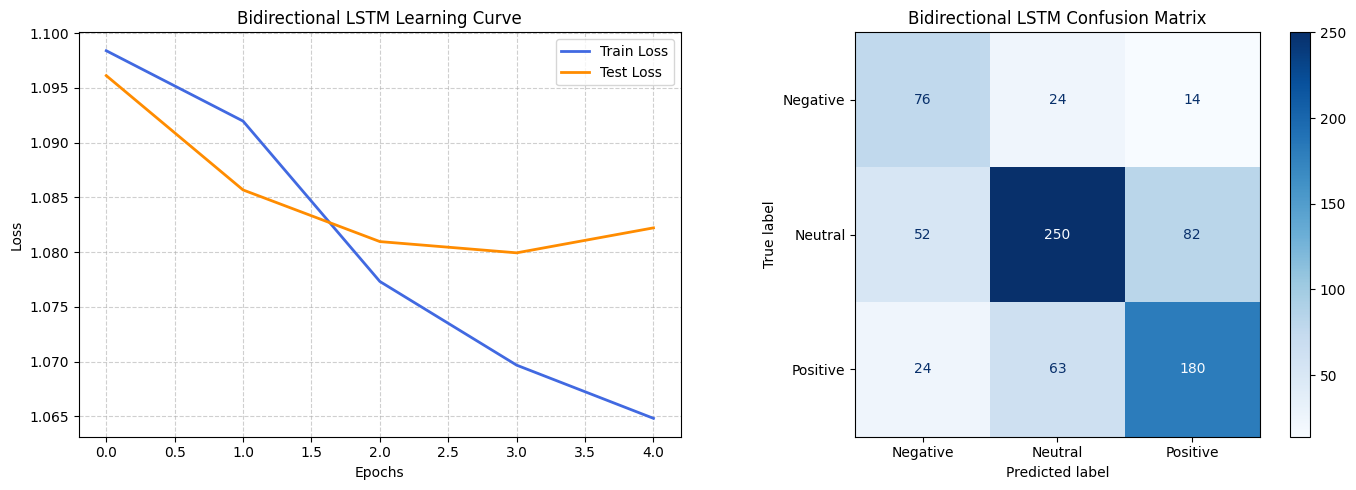


=================== BIDIRECTIONAL GRU TESTING EVALUATION ===================
Accuracy:  0.6484
Precision: 0.6231 (Macro)
Recall:    0.6704 (Macro)
F1 Score:  0.6335 (Macro)

Detailed Classification Report for Bidirectional GRU:
              precision    recall  f1-score   support

           0       0.46      0.73      0.57       114
           1       0.76      0.60      0.67       384
           2       0.64      0.68      0.66       267

    accuracy                           0.65       765
   macro avg       0.62      0.67      0.63       765
weighted avg       0.68      0.65      0.65       765



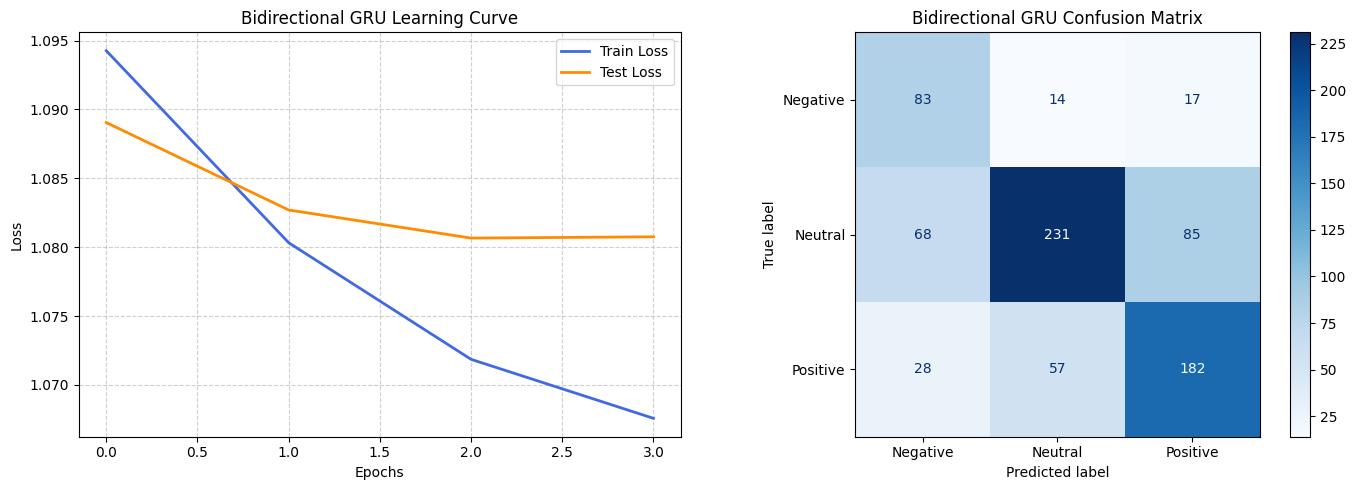

In [23]:
def evaluate_and_plot(model, history, test_loader, model_name="Model", device=device):
    model.eval()
    all_preds = []
    all_labels = []    
    
    with torch.no_grad():
        for seq, labels in test_loader:
            seq = seq.to(device)
            logits = model(seq)            
            probs = torch.softmax(logits, dim=1) 
            preds = torch.argmax(probs, dim=1)            
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())            
    
    acc = accuracy_score(all_labels, all_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    cm = confusion_matrix(all_labels, all_preds)
    
    print(f"\n=================== {model_name.upper()} TESTING EVALUATION ===================")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f} (Macro)")
    print(f"Recall:    {rec:.4f} (Macro)")
    print(f"F1 Score:  {f1:.4f} (Macro)")    
    
    print(f"\nDetailed Classification Report for {model_name}:")
    print(classification_report(
        all_labels, 
        all_preds, 
        target_names=["0", "1", "2"], 
        zero_division=0
    ))
    print("================================================================")

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))    
    
    ax[0].plot(history["train_loss"], label="Train Loss", color="royalblue", lw=2)
    ax[0].plot(history["test_loss"], label="Test Loss", color="darkorange", lw=2)
    ax[0].set_title(f"{model_name} Learning Curve")
    ax[0].set_xlabel("Epochs")
    ax[0].set_ylabel("Loss") 
    ax[0].legend()
    ax[0].grid(True, linestyle="--", alpha=0.6)    
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Neutral", "Positive"])
    disp.plot(ax=ax[1], cmap="Blues", values_format='d')
    ax[1].set_title(f"{model_name} Confusion Matrix")
    
    plt.tight_layout()
    plt.show()

evaluate_and_plot(lstm_model, lstm_history, test_loader, model_name="Bidirectional LSTM", device=device)
evaluate_and_plot(gru_model, gru_history, test_loader, model_name="Bidirectional GRU", device=device)

In [24]:
fast_tokenizer.save_pretrained("./saved_tokenizer")

torch.save(embedding_matrix, "embedding_matrix.pt")

torch.save(lstm_model.state_dict(), "lstm_model.pt")
torch.save(gru_model.state_dict(), "gru_model.pt")

print("All inference assets saved successfully!")

All inference assets saved successfully!
